# Pair 1: ControlNet vs InstructPix2Pix
Editing product photos (colour, material, scene) while keeping the product shape.

In [1]:
import os, time, shutil
import cv2, torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, StableDiffusionInstructPix2PixPipeline, UniPCMultistepScheduler
from transformers import CLIPModel, CLIPProcessor, ViTModel, ViTImageProcessor

device = "cuda"
out = "results/pair1"
neg = "lowres, blurry, deformed, distorted, watermark, text"
os.makedirs(out+"/images",exist_ok=True)
os.makedirs("results/summary",exist_ok=True)


In [2]:
products = [["berry_bowl", "bowl", "cobalt blue", "light oak wood", "on a marble kitchen bench"],
            ["candle", "candle", "sage green", "brushed copper", "on a bedside table next to a lamp"],
            ["clock", "clock", "matte black", "white marble", "on a bookshelf in a living room"],
            ["fancy_boot", "boot", "burgundy", "suede", "on a wooden porch in autumn"],
            ["shiny_sneaker", "sneaker", "bright red", "denim", "on a gym floor"],
            ["vase", "vase", "terracotta orange", "frosted glass", "on a dining table with flowers"],
            ["can", "can", "pastel pink", "brushed aluminium", "on a beach towel in the sun"],
            ["rc_car", "toy car", "lime green", "polished chrome", "on a child's bedroom carpet"]]

cases = []
for folder, name, colour, material, scene in products:
    path = f"data/dreambooth/{folder}/00.jpg"
    cases.append([folder+"_colour", "colour", path, name, f"a photo of a {colour} {name}", f"make the {name} {colour}"])
    cases.append([folder+"_material", "material", path, name, f"a photo of a {name} made of {material}", f"make the {name} out of {material}"])
    cases.append([folder+"_scene", "scene", path, name, f"a photo of a {name} {scene}", f"put the {name} {scene}"])
cases = pd.DataFrame(cases,columns=["case_id","edit_type","path","name","target","instruction"])
cases = cases.set_index("case_id",drop=False)

def load_image(path,size=512):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    s = min(w,h)
    left = (w-s)//2
    top = (h-s)//2
    img = img.crop((left,top,left+s,top+s))
    img = img.resize((size,size))
    return img

def canny(img):
    e = cv2.Canny(np.array(img),100,200)
    e = np.stack([e,e,e],axis=2)
    edges = Image.fromarray(e)
    return edges

## Generation
Same seeds, 30 steps, guidance 7.5 and negative prompt for both models. Ablation = control strength (seed 0).

In [3]:
def edit(pipe,model,c,seed,scale,steps=30):
    src = load_image(c.path)
    g = torch.Generator(device).manual_seed(seed)
    if model=="controlnet":
        result = pipe(c.target,image=canny(src),controlnet_conditioning_scale=scale,
                      negative_prompt=neg,num_inference_steps=steps,guidance_scale=7.5,generator=g)
    else:
        result = pipe(c.instruction,image=src,image_guidance_scale=scale,
                      negative_prompt=neg,num_inference_steps=steps,guidance_scale=7.5,generator=g)
    return result

log = []
for model in ["controlnet", "ip2p"]:
    t = time.time()
    if model=="controlnet":
        cn = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny",torch_dtype=torch.float16)
        pipe = StableDiffusionControlNetPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5",controlnet=cn,torch_dtype=torch.float16)
        pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
        scales = [1.0, 0.5, 1.5]   #first one is the main setting
    else:
        pipe = StableDiffusionInstructPix2PixPipeline.from_pretrained("timbrooks/instruct-pix2pix",torch_dtype=torch.float16)
        scales = [1.5, 1.0, 2.0]
    pipe = pipe.to(device)
    pipe.set_progress_bar_config(disable=True)
    print(model,"loaded in",round(time.time()-t,1),"s")
    edit(pipe,model,cases.iloc[0],123,scales[0],steps=5)   #warm-up, not timed

    for scale in scales:
        setting = "main"
        seeds = [0, 1]
        if scale!=scales[0]:
            setting = "ablation"
            seeds = [0]
        for c in cases.itertuples():
            for seed in seeds:
                torch.cuda.reset_peak_memory_stats()
                t = time.time()
                result = edit(pipe,model,c,seed,scale)
                torch.cuda.synchronize()
                sec = time.time()-t
                memory = torch.cuda.max_memory_allocated()/1024**2
                file = f"{out}/images/{model}_{c.case_id}_scale{scale}_seed{seed}.png"
                result.images[0].save(file)
                flag = False
                if result.nsfw_content_detected:
                    flag = result.nsfw_content_detected[0]
                log.append([model, c.case_id, c.edit_type, seed, scale, setting, sec, memory, flag, file])
                print(model,c.case_id,seed,scale,round(sec,2),"s")
    del pipe
    torch.cuda.empty_cache()

log = pd.DataFrame(log,columns=["model","case_id","edit_type","seed","scale","setting","seconds","memory_mb","safety_flag","file"])
log.to_csv(out+"/generation_log.csv",index=False)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

controlnet loaded in 7.1 s
controlnet berry_bowl_colour 0 1.0 9.6 s
controlnet berry_bowl_colour 1 1.0 9.15 s
controlnet berry_bowl_material 0 1.0 9.28 s
controlnet berry_bowl_material 1 1.0 9.14 s
controlnet berry_bowl_scene 0 1.0 9.12 s
controlnet berry_bowl_scene 1 1.0 9.13 s
controlnet candle_colour 0 1.0 9.29 s
controlnet candle_colour 1 1.0 9.17 s
controlnet candle_material 0 1.0 9.42 s
controlnet candle_material 1 1.0 9.38 s
controlnet candle_scene 0 1.0 9.17 s
controlnet candle_scene 1 1.0 9.19 s
controlnet clock_colour 0 1.0 9.14 s
controlnet clock_colour 1 1.0 9.14 s
controlnet clock_material 0 1.0 9.15 s
controlnet clock_material 1 1.0 9.23 s
controlnet clock_scene 0 1.0 9.28 s
controlnet clock_scene 1 1.0 9.4 s
controlnet fancy_boot_colour 0 1.0 9.26 s
controlnet fancy_boot_colour 1 1.0 9.36 s
controlnet fancy_boot_material 0 1.0 9.36 s
controlnet fancy_boot_material 1 1.0 9.23 s
controlnet fancy_boot_scene 0 1.0 9.37 s
controlnet fancy_boot_scene 1 1.0 9.25 s
controlnet sh

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

ip2p loaded in 6.9 s
ip2p berry_bowl_colour 0 1.5 7.02 s
ip2p berry_bowl_colour 1 1.5 7.11 s
ip2p berry_bowl_material 0 1.5 6.93 s
ip2p berry_bowl_material 1 1.5 7.06 s
ip2p berry_bowl_scene 0 1.5 7.21 s
ip2p berry_bowl_scene 1 1.5 7.13 s
ip2p candle_colour 0 1.5 7.03 s
ip2p candle_colour 1 1.5 7.07 s
ip2p candle_material 0 1.5 7.04 s
ip2p candle_material 1 1.5 7.11 s
ip2p candle_scene 0 1.5 6.96 s
ip2p candle_scene 1 1.5 6.97 s
ip2p clock_colour 0 1.5 6.93 s
ip2p clock_colour 1 1.5 6.93 s
ip2p clock_material 0 1.5 6.94 s
ip2p clock_material 1 1.5 6.94 s
ip2p clock_scene 0 1.5 6.96 s
ip2p clock_scene 1 1.5 6.99 s
ip2p fancy_boot_colour 0 1.5 7.06 s
ip2p fancy_boot_colour 1 1.5 7.03 s
ip2p fancy_boot_material 0 1.5 7.03 s
ip2p fancy_boot_material 1 1.5 7.02 s
ip2p fancy_boot_scene 0 1.5 7.01 s
ip2p fancy_boot_scene 1 1.5 7.03 s
ip2p shiny_sneaker_colour 0 1.5 6.99 s
ip2p shiny_sneaker_colour 1 1.5 7.23 s
ip2p shiny_sneaker_material 0 1.5 7.16 s
ip2p shiny_sneaker_material 1 1.5 7.14 s
i

## Metrics
CLIP-T and CLIP direction (higher = better), DINO structure distance (lower = shape kept), edge F1 (higher = better, favours ControlNet).

In [4]:
clip = CLIPModel.from_pretrained("openai/clip-vit-large-patch14").to(device)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")
dino = ViTModel.from_pretrained("facebook/dino-vitb8",add_pooling_layer=False).to(device)
dino_proc = ViTImageProcessor.from_pretrained("facebook/dino-vitb8")

#save the keys of DINO's last attention layer
keys = {}
def save_keys(module,inp,output):
    keys["k"] = output
dino.encoder.layer[-1].attention.attention.key.register_forward_hook(save_keys)

def clip_image(img):
    inputs = clip_proc(images=img,return_tensors="pt").to(device)
    with torch.no_grad():
        e = clip.get_image_features(**inputs)[0]
    e = e/e.norm()
    return e

def clip_text(text):
    inputs = clip_proc(text=[text],return_tensors="pt",padding=True).to(device)
    with torch.no_grad():
        e = clip.get_text_features(**inputs)[0]
    e = e/e.norm()
    return e

def self_sim(img):
    inputs = dino_proc(images=img,return_tensors="pt").to(device)
    with torch.no_grad():
        dino(**inputs)
    k = keys["k"][0]
    k = k/k.norm(dim=1,keepdim=True)
    sim = k@k.T
    return sim

def edges(img):
    gray = np.array(img.convert("L"))
    e = cv2.Canny(gray,100,200)>0
    return e

def edge_f1(a,b):
    ea = edges(a)
    eb = edges(b)
    kernel = np.ones((5,5),np.uint8)   #2 pixel tolerance
    ea_wide = cv2.dilate(ea.astype(np.uint8),kernel)>0
    eb_wide = cv2.dilate(eb.astype(np.uint8),kernel)>0
    overlap_a = (eb & ea_wide).sum()
    overlap_b = (ea & eb_wide).sum()
    precision = overlap_a/max(eb.sum(),1)
    recall = overlap_b/max(ea.sum(),1)
    if precision+recall==0:
        return 0.0
    f1 = 2*precision*recall
    f1 = f1/(precision+recall)
    return f1

rows = []
for x in log.itertuples():
    c = cases.loc[x.case_id]
    src = load_image(c.path)
    img = Image.open(x.file).convert("RGB")
    i_src = clip_image(src)
    i_edit = clip_image(img)
    t_src = clip_text("a photo of a "+c["name"])
    t_tgt = clip_text(c.target)

    clip_t = (i_edit@t_tgt).item()
    direction = torch.cosine_similarity(i_edit-i_src,t_tgt-t_src,dim=0).item()
    diff = self_sim(src)-self_sim(img)
    structure = (diff**2).mean().item()
    rows.append([clip_t, direction, structure, edge_f1(src,img)])

log[["clip_t","clip_direction","structure_distance","edge_f1"]] = rows
log.to_csv(out+"/metrics.csv",index=False)

## Results
Means with 95% bootstrap CIs over the 24 cases, and the paired difference A-B.

In [5]:
def bootstrap_ci(values,n=5000):
    rng = np.random.default_rng(0)
    means = []
    for i in range(n):
        sample = rng.choice(values,len(values))
        means.append(sample.mean())
    low, high = np.percentile(means,[2.5,97.5])
    return low, high

metrics = ["clip_t", "clip_direction", "structure_distance", "edge_f1", "seconds", "memory_mb"]
main = log[log.setting=="main"]
a = main[main.model=="controlnet"].groupby("case_id")[metrics].mean()
b = main[main.model=="ip2p"].groupby("case_id")[metrics].mean()

summary = []
paired = []
for m in metrics:
    low, high = bootstrap_ci(a[m].values)
    summary.append(["controlnet", m, a[m].mean(), low, high])
    low, high = bootstrap_ci(b[m].values)
    summary.append(["ip2p", m, b[m].mean(), low, high])
    diff = a[m]-b[m]
    low, high = bootstrap_ci(diff.values)
    a_better = (diff>0).mean()*100
    paired.append([m, diff.mean(), low, high, a_better])

summary = pd.DataFrame(summary,columns=["model","metric","mean","ci_low","ci_high"])
paired = pd.DataFrame(paired,columns=["metric","A_minus_B","ci_low","ci_high","A_higher_%"])
summary.to_csv("results/summary/pair1_summary.csv",index=False)
paired.to_csv("results/summary/pair1_paired.csv",index=False)
print(summary.round(4))
print(paired.round(4))
print(main.groupby(["model","edit_type"])[["clip_t","clip_direction","structure_distance"]].mean().round(4))
print("safety flags:",log.safety_flag.sum())

         model              metric       mean     ci_low    ci_high
0   controlnet              clip_t     0.2609     0.2489     0.2719
1         ip2p              clip_t     0.2595     0.2464     0.2718
2   controlnet      clip_direction     0.1121     0.0927     0.1317
3         ip2p      clip_direction     0.1393     0.1186     0.1610
4   controlnet  structure_distance     0.0514     0.0370     0.0706
5         ip2p  structure_distance     0.0462     0.0235     0.0777
6   controlnet             edge_f1     0.7099     0.6555     0.7629
7         ip2p             edge_f1     0.7157     0.6130     0.8077
8   controlnet             seconds     9.3255     9.2742     9.3777
9         ip2p             seconds     7.0483     7.0057     7.0924
10  controlnet           memory_mb  3983.2134  3983.2134  3983.2134
11        ip2p           memory_mb  3958.2197  3958.2197  3958.2197
               metric  A_minus_B   ci_low  ci_high  A_higher_%
0              clip_t     0.0013  -0.0123   0.0151   

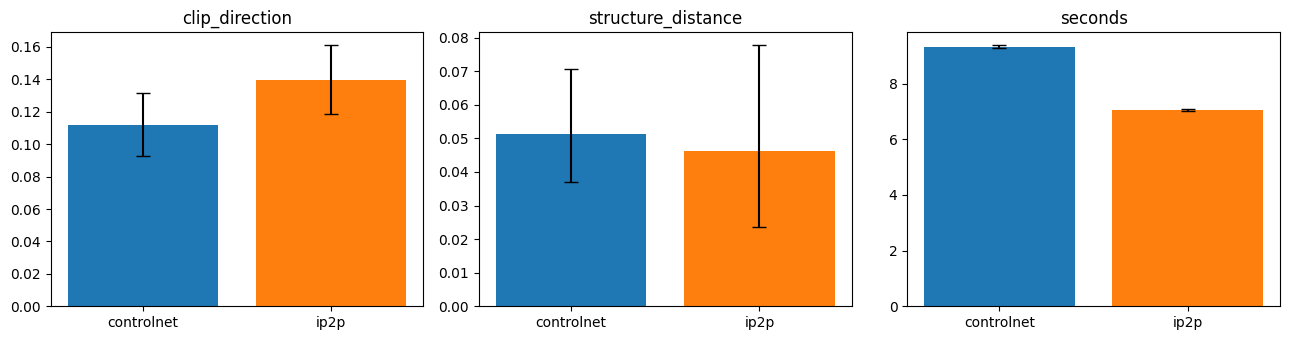

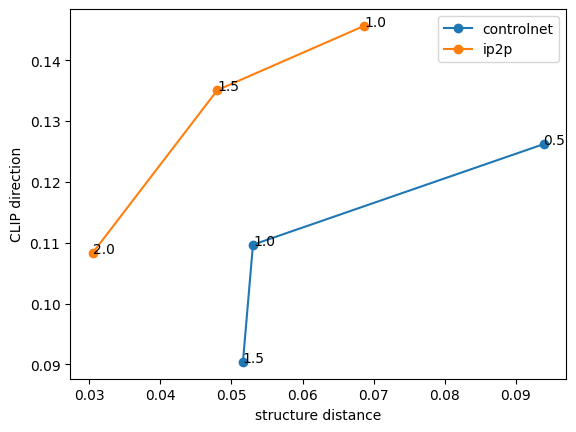

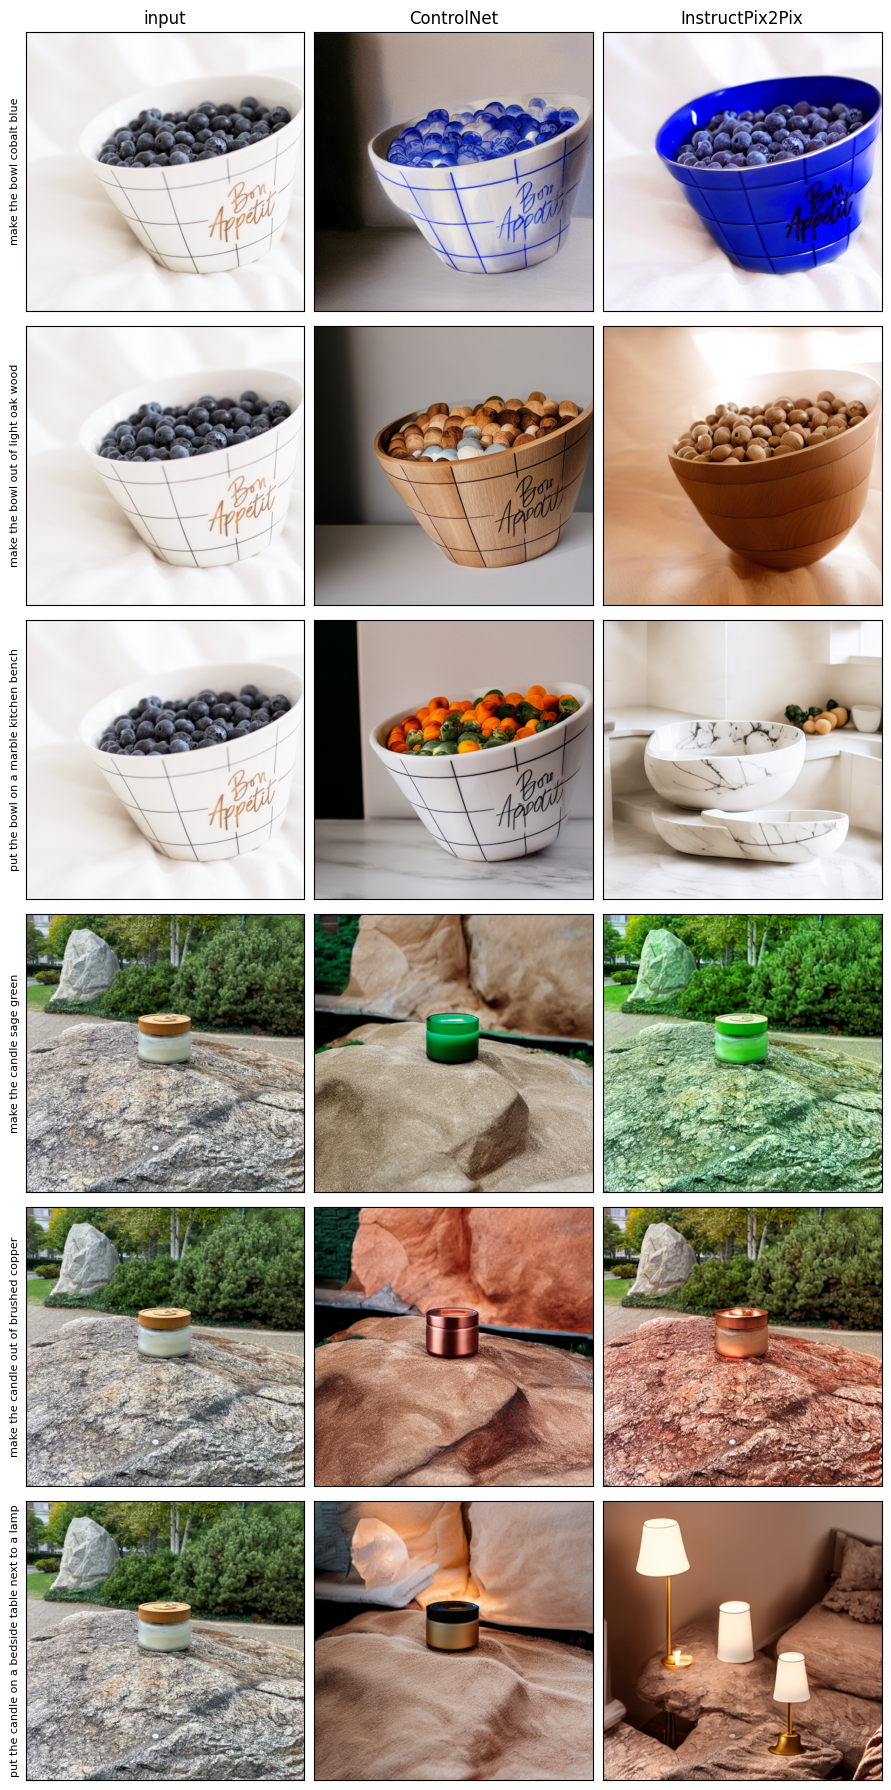

In [6]:
fig, ax = plt.subplots(1,3,figsize=(13,3.5))
for i, m in enumerate(["clip_direction", "structure_distance", "seconds"]):
    s = summary[summary.metric==m]
    err = [s["mean"]-s.ci_low, s.ci_high-s["mean"]]
    ax[i].bar(s.model,s["mean"],yerr=err,capsize=5,color=["tab:blue","tab:orange"])
    ax[i].set_title(m)
plt.tight_layout()
plt.savefig("results/summary/pair1_bars.png",dpi=200)
plt.show()

abl = log[log.seed==0].groupby(["model","scale"])[["clip_direction","structure_distance"]].mean().reset_index()
abl.to_csv("results/summary/pair1_ablation.csv",index=False)
for model in ["controlnet", "ip2p"]:
    a = abl[abl.model==model]
    plt.plot(a.structure_distance,a.clip_direction,"o-",label=model)
    for r in a.itertuples():
        plt.annotate(str(r.scale),(r.structure_distance,r.clip_direction))
plt.xlabel("structure distance")
plt.ylabel("CLIP direction")
plt.legend()
plt.savefig("results/summary/pair1_ablation.png",dpi=200)
plt.show()

fig, ax = plt.subplots(6,3,figsize=(9,18))
for i in range(6):
    c = cases.iloc[i]
    ax[i][0].imshow(load_image(c.path))
    ax[i][1].imshow(Image.open(f"{out}/images/controlnet_{c.case_id}_scale1.0_seed0.png"))
    ax[i][2].imshow(Image.open(f"{out}/images/ip2p_{c.case_id}_scale1.5_seed0.png"))
    ax[i][0].set_ylabel(c.instruction,fontsize=8)
ax[0][0].set_title("input")
ax[0][1].set_title("ControlNet")
ax[0][2].set_title("InstructPix2Pix")
plt.setp(ax,xticks=[],yticks=[])
plt.tight_layout()
plt.savefig(out+"/examples.png",dpi=150)
plt.show()

## Blind rating sheet
Images are copied with random names. I rate them in `results/ratings/ratings_pair1.csv`.

In [7]:
os.makedirs("results/ratings/pair1_images",exist_ok=True)
rate = main[main.seed==0].sample(frac=1,random_state=1).reset_index(drop=True)
names = []
for i in range(len(rate)):
    names.append(f"img_{i:03d}.png")
rate["blind_name"] = names
for x in rate.itertuples():
    shutil.copy(x.file,"results/ratings/pair1_images/"+x.blind_name)
rate[["blind_name","model","case_id"]].to_csv("results/ratings/pair1_key_DO_NOT_OPEN.csv",index=False)

sheet = rate[["blind_name","case_id"]].merge(cases[["case_id","instruction"]].reset_index(drop=True),on="case_id")
sheet = sheet.drop(columns="case_id")
for col in ["edit_done_1to5", "product_kept_1to5", "realistic_1to5", "usable_0or1"]:
    sheet[col] = ""
sheet.to_csv("results/ratings/ratings_pair1.csv",index=False)
print(len(sheet),"images to rate")

48 images to rate
